<a href="https://colab.research.google.com/github/Susanta2006/Colab/blob/main/PDS_Week7_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic Dataset Exploratory Data Analysis and Survival Prediction

**Author:** Susanta Banik  
**Roll Number:** B24BS2374

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data=pd.read_csv("/content/Titanic-Dataset.csv")
print(data.head(10))

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54

In [5]:
data = data.dropna()
print(data.head(10))

    PassengerId  Survived  Pclass  \
1             2         1       1   
3             4         1       1   
6             7         0       1   
10           11         1       3   
11           12         1       1   
21           22         1       2   
23           24         1       1   
27           28         0       1   
52           53         1       1   
54           55         0       1   

                                                 Name     Sex   Age  SibSp  \
1   Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
3        Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
6                             McCarthy, Mr. Timothy J    male  54.0      0   
10                    Sandstrom, Miss. Marguerite Rut  female   4.0      1   
11                           Bonnell, Miss. Elizabeth  female  58.0      0   
21                              Beesley, Mr. Lawrence    male  34.0      0   
23                       Sloper, Mr. William T

### 1. Variation of Surviving Passengers v/s Their Age and Gender
We will plot a histogram/density plot comparing the ages of survivors and non-survivors, segmented by gender.

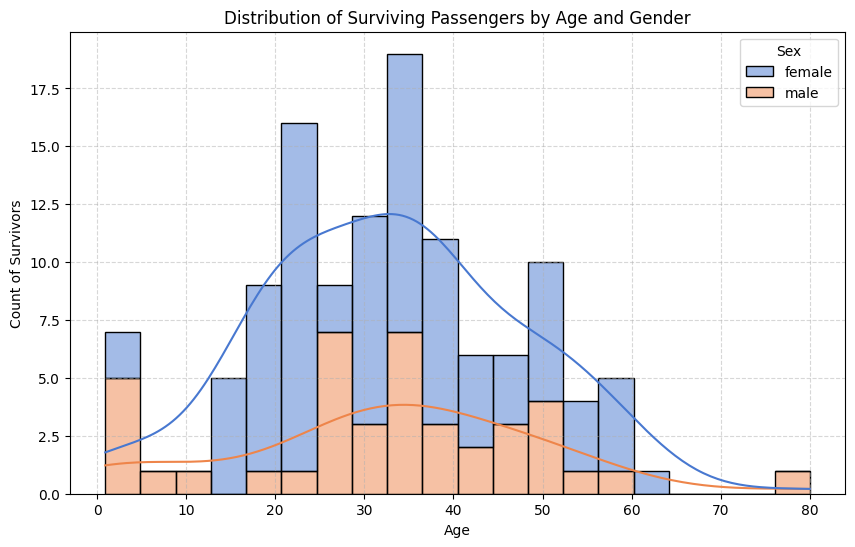

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for survivors to analyze their age and gender distribution
survived_data = data[data['Survived'] == 1]

plt.figure(figsize=(10, 6))
sns.histplot(data=survived_data, x='Age', hue='Sex', multiple='stack', kde=True, bins=20, palette='muted')
plt.title('Distribution of Surviving Passengers by Age and Gender')
plt.xlabel('Age')
plt.ylabel('Count of Survivors')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 2. Variation of Fare v/s Passenger Class, showing Gender and Age
We will use a scatter plot (or stripplot) where the x-axis represents the passenger class, the y-axis represents the fare, the color represents gender, and the size of the points represents age.

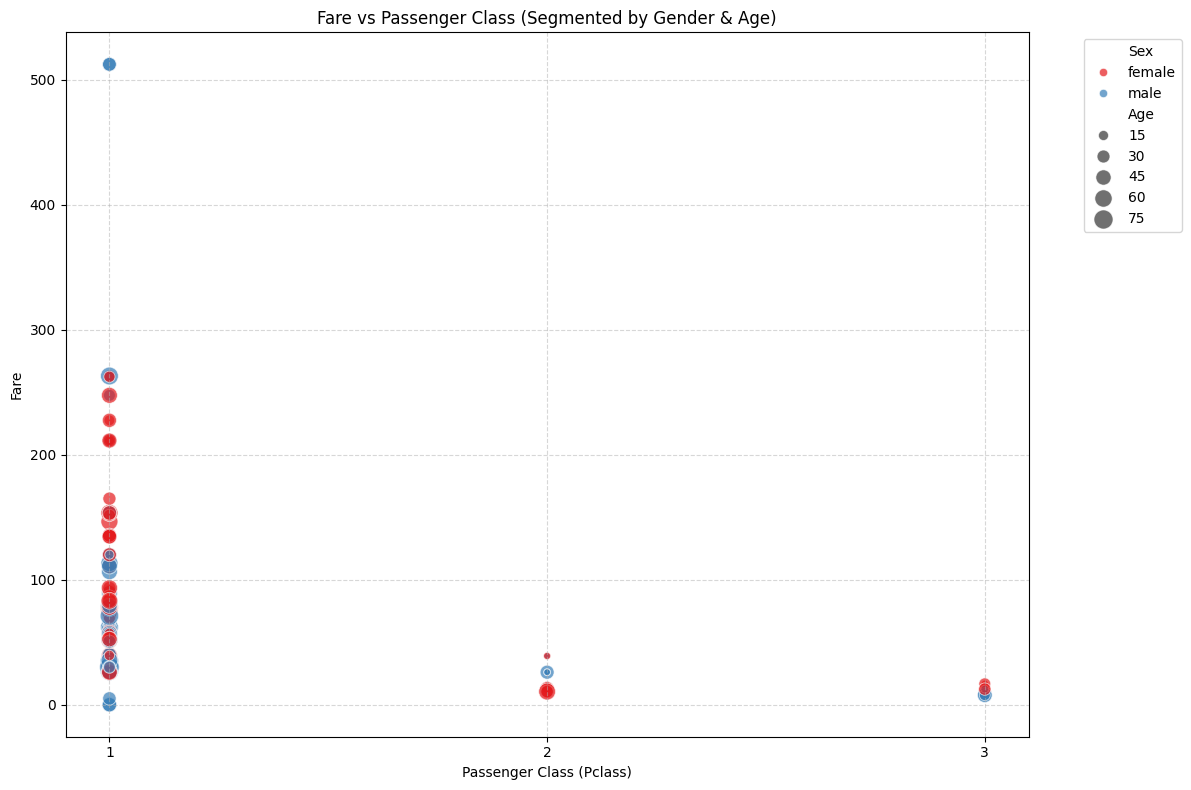

In [7]:
plt.figure(figsize=(12, 8))
sns.scatterplot(data=data, x='Pclass', y='Fare', hue='Sex', size='Age', sizes=(20, 200), alpha=0.7, palette='Set1')
plt.title('Fare vs Passenger Class (Segmented by Gender & Age)')
plt.xlabel('Passenger Class (Pclass)')
plt.ylabel('Fare')
plt.xticks([1, 2, 3])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 3. Survival Rate of Male and Female Passengers v/s Passenger Class
We will use a pointplot or barplot to represent the proportion of survivors across different classes, separated by gender.

/tmp/ipykernel_1683/1285910129.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=data, x='Pclass', y='Survived', hue='Sex', palette='deep', ci=None)


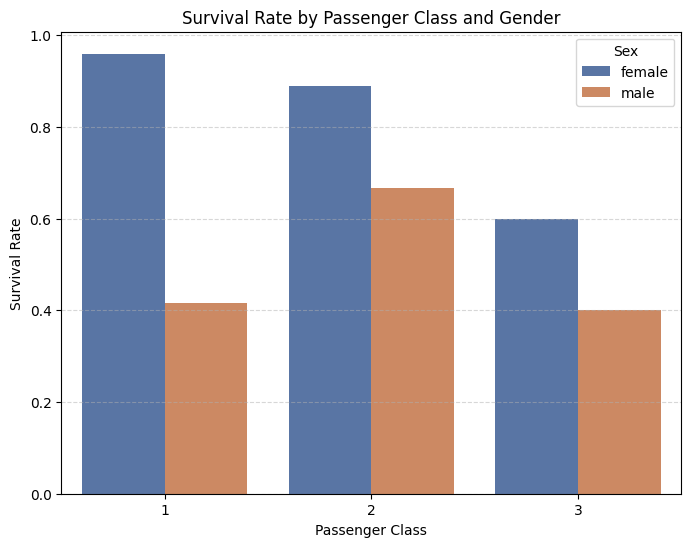

In [8]:
plt.figure(figsize=(8, 6))
sns.barplot(data=data, x='Pclass', y='Survived', hue='Sex', palette='deep', ci=None)
plt.title('Survival Rate by Passenger Class and Gender')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.show()

### 4. What sorts of people were more likely to survive?
Let's run a quick statistical breakdown grouping the data by socio-economic class (Pclass), Gender (Sex), and Age group to summarize who had the highest survival rates.

In [9]:
# Categorize age into groups
data['AgeGroup'] = pd.cut(data['Age'], bins=[0, 12, 18, 50, 100], labels=['Child', 'Teenager', 'Adult', 'Senior'])

# Group and calculate survival rates
survival_summary = data.groupby(['Sex', 'Pclass', 'AgeGroup'])['Survived'].mean().reset_index()
survival_summary = survival_summary.sort_values(by='Survived', ascending=False)

display(survival_summary.head(10))

/tmp/ipykernel_1683/754267558.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['AgeGroup'] = pd.cut(data['Age'], bins=[0, 12, 18, 50, 100], labels=['Child', 'Teenager', 'Adult', 'Senior'])
/tmp/ipykernel_1683/754267558.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival_summary = data.groupby(['Sex', 'Pclass', 'AgeGroup'])['Survived'].mean().reset_index()


,Sex,Pclass,AgeGroup,Survived
1,female,1,Teenager,1.000000
16,male,2,Child,1.000000
3,female,1,Senior,1.000000
4,female,2,Child,1.000000
6,female,2,Adult,1.000000
12,male,1,Child,1.000000
20,male,3,Child,1.000000
2,female,1,Adult,0.961538
10,female,3,Adult,0.666667
13,male,1,Teenager,0.500000
